# Modelo de estimación de precios de vivienda (E7, primera versión)

¿Qué tan bien se puede estimar el **precio de mercado** de un inmueble con los datos del barrido diario,
y es mejor que la **mediana del m² de sus comparables** que usa hoy la alerta?

**Datos:** los avisos de venta **activos** de `estado/avisos` (barrido nacional, `src/consolidar.py`), solo
vivienda: apartamentos, apartaestudios y casas. Son **precios pedidos**, no de cierre.

**Qué se mide:**

1. **Error** del modelo frente a dos líneas base: la mediana del m² por barrio y los comparables de la alerta.
2. **Validación honesta:** el mismo inmueble nunca está en entrenamiento y prueba, y una prueba
   **temporal** (entrenar con lo publicado hasta septiembre, predecir los avisos nuevos de octubre).
3. **Rangos de confianza** (p10–p90) y si de verdad contienen el 80% de los casos.
4. **Qué variables pesan** en el precio.
5. **Aplicación:** cómo se vería la alerta de Cali si el descuento se midiera contra el modelo.

> Una estimación de este modelo **no es un avalúo** (Ley 1673 de 2013): es una "estimación de precio de
> mercado" sobre precios pedidos.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE))
from src import modelo_precio as mp     # carga, limpieza, variables, particiones y métricas (comunes)

pd.set_option("display.width", 140)
TIPOS, SEMILLA = mp.TIPOS, mp.SEMILLA

# Paleta (modelo = azul, línea base = naranja; texto en tinta neutra, nunca del color de la serie)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#a8a69f"
TINTA, TINTA_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d4ce",
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "axes.grid": True, "grid.color": "#e8e6e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5, "legend.frameon": False,
})
pct = lambda x: f"{x:.1%}".replace(".", ",")
mil = lambda x: f"{x:,.0f}".replace(",", ".")

## 1. Datos

In [2]:
meta = json.loads((mp.AVISOS.parent / "meta.json").read_text())       # actualizar: python -m src.consolidar --bajar
a = mp.cargar()
print(f"Estado al {meta['ultimo_barrido']} · vivienda activa: {mil(len(a))}")
a["tipo"].value_counts().to_frame("avisos")

Estado al 2026-10-26 · vivienda activa: 129.346


,avisos
tipo,
Apartamento,81578
Casa,43491
Apartaestudio,4277


## 2. Limpieza

Solo se quitan **errores evidentes**; los precios caros o baratos de verdad se quedan (si se quitaran,
el error medido en la prueba saldría artificialmente bajo). Las reglas están en `src/modelo_precio.py`
(`limpiar`):

| Regla | Por qué |
|---|---|
| Sin precio (en dólares) o área fuera de 15–3.000 m² | No se puede calcular el precio por m² |
| Precio por m² fuera de 0,8–35 millones | Errores de digitación (un cero de más o de menos) |
| Más de ~3,3 veces arriba o abajo de la mediana de su ciudad y tipo | Casi siempre precio o área mal escritos |
| Duplicados exactos (ciudad, barrio, tipo, precio, área, habitaciones, baños) | El mismo aviso publicado dos veces |

In [3]:
a, pasos = mp.limpiar(a)
pasos

,avisos
paso,
Vivienda activa,129346
Con precio en pesos y área 15–3.000 m²,128487
"Precio/m² entre 0,8 y 35 M",127942
Sin extremos frente a su ciudad y tipo,126709
Sin duplicados exactos,122387


## 3. Variables

- **Inmueble:** área (total, construida y de terreno), habitaciones, baños, parqueaderos, piso, estrato,
  antigüedad (código 1–5), estado físico, si es proyecto, número de fotos.
- **Administración por m²** (0 = no informada → vacío): es un buen indicio del tipo de edificio.
- **Ubicación:** coordenadas, departamento y, codificados por su precio medio (*target encoding* con
  validación cruzada, para no filtrar la respuesta), la ciudad, el barrio, la zona y la comuna.
- **Amenidades:** las 40 más comunes, como 0/1.

El objetivo es el **logaritmo del precio por m²**; el precio estimado es `exp(predicción) × área`.
Todo esto está en `src/modelo_precio.py` (`variables`, `grupos`).

In [4]:
X, TE, AMENIDADES = mp.variables(a)
y = a["lpm2"].to_numpy()
grupo = mp.grupos(a)        # mismo inmueble = mismas coordenadas, área y habitaciones
print(f"{X.shape[1]} variables + {TE.shape[1]} codificadas · {mil(grupo.nunique())} inmuebles distintos en {mil(len(a))} avisos")

57 variables + 4 codificadas · 112.313 inmuebles distintos en 122.387 avisos


## 4. Entrenamiento y líneas base

- **Modelo:** *gradient boosting* de histogramas (`HistGradientBoostingRegressor` de scikit-learn, sin
  dependencias nuevas), con parada temprana.
- **Línea base 1 · mediana por niveles:** la mediana del precio/m² de entrenamiento en el mismo
  barrio, tipo y estrato (con al menos 5 avisos); si no alcanza, barrio y tipo; luego ciudad, tipo y estrato;
  luego ciudad y tipo.
- **Línea base 2 · comparables de la alerta** (solo Cali, sección 6): la regla exacta de
  `src/oportunidades.py`.

**Métricas:** error porcentual absoluto mediano (*MdAPE*) y la proporción de avisos estimados dentro de
±10% y ±20% de su precio.

In [5]:
def entrenar(X, TE, y, **kw):
    enc = mp.codificador()
    Xc = X.copy()
    Xc[["te_" + c for c in TE.columns]] = enc.fit_transform(TE, y)      # validación cruzada interna
    m = HistGradientBoostingRegressor(max_iter=3000, learning_rate=0.05, max_leaf_nodes=63,
                                      min_samples_leaf=20, l2_regularization=1.0,
                                      categorical_features="from_dtype", early_stopping=True,
                                      validation_fraction=0.1, n_iter_no_change=50,
                                      random_state=SEMILLA, **kw)
    m.fit(Xc, y)
    return m, enc

def predecir(modelo, X, TE):
    m, enc = modelo
    Xc = X.copy()
    Xc[["te_" + c for c in TE.columns]] = enc.transform(TE)
    return m.predict(Xc)

error, metricas, linea_base = mp.error, mp.metricas, mp.linea_base

d = a.assign(estrato=X["estrato"])          # el estrato ya limpio (1–6)

## 5. Validación por grupos (el mismo inmueble nunca en entrenamiento y prueba)

80% para entrenar y 20% para probar, partido por **inmueble** y no por aviso: si el mismo apartamento está
publicado por dos inmobiliarias, las dos copias van al mismo lado. Sin esto el error sale engañosamente bajo.

In [6]:
t0 = time.time()
i_tr, i_te = mp.particion_grupos(grupo)
modelo = entrenar(X.iloc[i_tr], TE.iloc[i_tr], y[i_tr])
p_mod = predecir(modelo, X.iloc[i_te], TE.iloc[i_te])
p_base = linea_base(d.iloc[i_tr], d.iloc[i_te])
e_mod, e_base = error(p_mod, y[i_te]), error(p_base, y[i_te])
print(f"Entrenado en {time.time() - t0:.0f} s · {modelo[0].n_iter_} árboles · "
      f"{mil(len(i_tr))} avisos para entrenar, {mil(len(i_te))} para probar")
res = pd.DataFrame({"Modelo": metricas(e_mod), "Mediana por barrio": metricas(e_base)}).T
res.style.format({"MdAPE": pct, "±10%": pct, "±20%": pct, "avisos": mil})

Entrenado en 11 s · 2171 árboles · 97.856 avisos para entrenar, 24.531 para probar


,MdAPE,±10%,±20%,avisos
Modelo,"11,9%","43,9%","71,5%",24.531
Mediana por barrio,"17,6%","31,3%","55,0%",24.531


In [7]:
prueba = d.iloc[i_te].assign(e_mod=e_mod, e_base=e_base)
ciudades = prueba["ciudad"].value_counts().head(10).index
por_ciudad = (prueba[prueba["ciudad"].isin(ciudades)].groupby("ciudad")
              .agg(avisos=("e_mod", "size"), modelo=("e_mod", "median"), base=("e_base", "median"))
              .sort_values("avisos", ascending=False))
por_tipo = prueba.groupby("tipo").agg(avisos=("e_mod", "size"), modelo=("e_mod", "median"),
                                      base=("e_base", "median"))
prueba["rango"] = pd.qcut(prueba["precio"], 5, labels=["20% más barato", "2.º quintil", "3.º quintil",
                                                       "4.º quintil", "20% más caro"])
por_rango = prueba.groupby("rango", observed=True).agg(avisos=("e_mod", "size"), modelo=("e_mod", "median"),
                                                       base=("e_base", "median"))
formato = {"modelo": pct, "base": pct, "avisos": mil}
display(por_ciudad.style.format(formato).set_caption("Error mediano por ciudad (10 con más avisos)"))
display(por_tipo.style.format(formato).set_caption("Por tipo"))
display(por_rango.style.format(formato).set_caption("Por rango de precio"))

,avisos,modelo,base
ciudad,,,
Bogotá,5.953,"10,8%","18,4%"
Medellín,2.931,"12,4%","19,0%"
Cali,1.741,"12,1%","18,5%"
Barranquilla,1.325,"13,1%","22,3%"
Envigado,1.140,"10,4%","13,4%"
Cartagena,906,"15,6%","21,6%"
Manizales,779,"12,5%","18,3%"
Pereira,705,"13,2%","16,7%"
Sabaneta,585,"9,0%","11,3%"


,avisos,modelo,base
tipo,,,
Apartaestudio,826,"10,0%","16,2%"
Apartamento,15.513,"10,2%","15,5%"
Casa,8.192,"16,5%","22,3%"


,avisos,modelo,base
rango,,,
20% más barato,5.071,"9,7%","14,4%"
2.º quintil,4.742,"10,6%","16,3%"
3.º quintil,4.997,"10,8%","17,5%"
4.º quintil,4.815,"12,7%","18,5%"
20% más caro,4.906,"16,8%","21,8%"


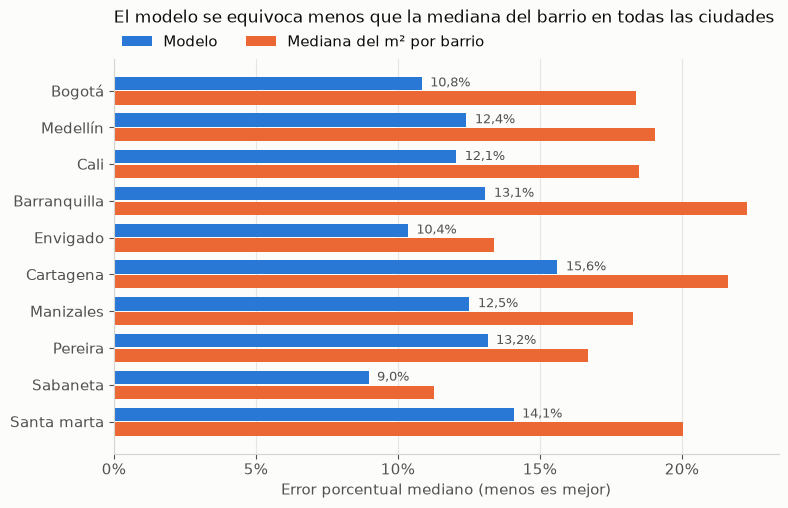

In [8]:
fig, ax = plt.subplots(figsize=(8, 5.2))
filas = por_ciudad.iloc[::-1]
yy = np.arange(len(filas))
alto = 0.36
ax.barh(yy + alto / 2 + 0.02, filas["modelo"], height=alto, color=AZUL, label="Modelo")
ax.barh(yy - alto / 2 - 0.02, filas["base"], height=alto, color=NARANJA, label="Mediana del m² por barrio")
for i, v in enumerate(filas["modelo"]):
    ax.text(v + 0.003, i + alto / 2 + 0.02, pct(v), va="center", fontsize=9, color=TINTA_2)
ax.set_yticks(yy, filas.index)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Error porcentual mediano (menos es mejor)")
ax.set_title("El modelo se equivoca menos que la mediana del barrio en todas las ciudades",
             loc="left", fontsize=12, color=TINTA, pad=26)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
plt.tight_layout()
plt.show()

## 6. Validación temporal: los avisos nuevos de octubre

La alerta califica **avisos recién publicados**. Aquí el modelo se entrena solo con lo publicado
**antes del 1 de octubre** y predice lo publicado **desde el 1 de octubre**. Se quitan de la prueba los
inmuebles que ya estaban en el entrenamiento (re-publicaciones).

In [9]:
CORTE = "2026-10-01"
t_tr, t_te = mp.particion_temporal(a, grupo, CORTE)
modelo_t = entrenar(X.iloc[t_tr], TE.iloc[t_tr], y[t_tr])
pt_mod = predecir(modelo_t, X.iloc[t_te], TE.iloc[t_te])
pt_base = linea_base(d.iloc[t_tr], d.iloc[t_te])
et_mod, et_base = error(pt_mod, y[t_te]), error(pt_base, y[t_te])
print(f"Entrenamiento: {mil(len(t_tr))} avisos publicados antes del {CORTE} · prueba: {mil(len(t_te))} publicados después")
sesgo = np.median(np.exp(pt_mod - y[t_te]) - 1)
print(f"Sesgo mediano del modelo en los nuevos: {pct(sesgo)} (positivo = estima por encima del precio pedido)")
res_t = pd.DataFrame({"Modelo": metricas(et_mod), "Mediana por barrio": metricas(et_base)}).T
res_t.style.format({"MdAPE": pct, "±10%": pct, "±20%": pct, "avisos": mil})

Entrenamiento: 106.008 avisos publicados antes del 2026-10-01 · prueba: 14.459 publicados después
Sesgo mediano del modelo en los nuevos: -0,7% (positivo = estima por encima del precio pedido)


,MdAPE,±10%,±20%,avisos
Modelo,"11,1%","45,9%","74,9%",14.459
Mediana por barrio,"16,2%","33,0%","58,8%",14.459


## 7. Cali: frente a los comparables de la alerta

La línea base más exigente: la regla exacta de `src/oportunidades.py` (mismo tipo y estrato, área ±30%,
±1 habitación; en el barrio oficial, a menos de 1 km o en la comuna; mínimo 8). Se compara **solo en los
avisos de prueba que tienen comparables**, que son los que la alerta califica.

In [10]:
from src import fuente_http
from src.oportunidades import _comparables
from src.viz_map import limpiar_ciudad

cali = limpiar_ciudad(fuente_http.dataset_activo("venta"), "Cali")
cali = cali[cali["Tipo_propiedad"].isin(TIPOS)].copy()
for c in ["Estrato", "Habitaciones"]:
    cali[c] = pd.to_numeric(cali[c], errors="coerce")
ids_tr = set(a["id_inmueble"].iloc[i_tr].astype(str))
ids_te = a["id_inmueble"].iloc[i_te].astype(str)
pool = cali[cali["id_inmueble"].isin(ids_tr)]
casos = cali[cali["id_inmueble"].isin(set(ids_te))]

filas = []
for _, c in casos.iterrows():
    comps, nivel = _comparables(c, pool)
    filas.append({"id_inmueble": c["id_inmueble"], "nivel": nivel,
                  "pm2_comps": comps["precio_m2"].median() if nivel else np.nan})
comp = pd.DataFrame(filas)
pos = pd.Series(np.arange(len(i_te)), index=ids_te.to_numpy())
comp["e_mod"] = e_mod[pos.loc[comp["id_inmueble"]].to_numpy()]
comp["e_comps"] = np.abs(comp["pm2_comps"] / casos.set_index("id_inmueble").loc[comp["id_inmueble"], "precio_m2"].to_numpy() - 1)
con = comp[comp["nivel"].notna()]
print(f"Cali, avisos de prueba: {mil(len(comp))} · con comparables suficientes: {mil(len(con))} ({len(con) / len(comp):.0%})")
res_c = pd.DataFrame({"Modelo": metricas(con["e_mod"]), "Comparables de la alerta": metricas(con["e_comps"]),
                      "Modelo (todos, con o sin comparables)": metricas(comp["e_mod"])}).T
res_c.style.format({"MdAPE": pct, "±10%": pct, "±20%": pct, "avisos": mil})

Cali, avisos de prueba: 1.741 · con comparables suficientes: 1.392 (80%)


,MdAPE,±10%,±20%,avisos
Modelo,"11,1%","46,0%","73,4%",1.392
Comparables de la alerta,"14,5%","36,3%","64,0%",1.392
"Modelo (todos, con o sin comparables)","12,1%","43,4%","70,1%",1.741


## 8. Rangos de confianza (p10–p90)

Dos modelos más, de cuantiles 10 y 90: el rango entre ellos debería contener el precio real en el
**80%** de los casos. Los modelos de cuantiles suelen quedarse cortos, así que se **calibran** con
*conformal prediction*: se entrenan con el 80% del entrenamiento, se mide en el 20% restante cuánto hay que
ensanchar el rango para que contenga el 80%, y ese margen se aplica a la prueba.

In [11]:
i_fit, i_cal = mp.subparticion(i_tr, grupo, fraccion=0.2, semilla=1)
q10 = entrenar(X.iloc[i_fit], TE.iloc[i_fit], y[i_fit], loss="quantile", quantile=0.10)
q90 = entrenar(X.iloc[i_fit], TE.iloc[i_fit], y[i_fit], loss="quantile", quantile=0.90)
# Margen conformal: cuánto ensanchar (en log) para que el 80% de la calibración quede dentro
s = np.maximum(predecir(q10, X.iloc[i_cal], TE.iloc[i_cal]) - y[i_cal], y[i_cal] - predecir(q90, X.iloc[i_cal], TE.iloc[i_cal]))
margen = np.quantile(s, min(1, np.ceil((len(s) + 1) * 0.8) / len(s)))
p10, p90 = predecir(q10, X.iloc[i_te], TE.iloc[i_te]), predecir(q90, X.iloc[i_te], TE.iloc[i_te])
crudo = ((y[i_te] >= p10) & (y[i_te] <= p90)).mean()
p10, p90 = p10 - margen, p90 + margen
prueba["dentro"] = (y[i_te] >= p10) & (y[i_te] <= p90)
prueba["ancho"] = np.exp(p90 - p10) - 1
print(f"Cobertura p10–p90 sin calibrar: {pct(crudo)} → calibrada: {pct(prueba['dentro'].mean())} (objetivo 80%) · "
      f"margen ×{np.exp(margen):.3f} a cada lado")
print(f"Ancho mediano: el extremo alto es {prueba['ancho'].median():.0%} más que el bajo "
      f"(p. ej. un inmueble estimado en 400 M: entre {400 * np.exp(np.median(p10 - p_mod)):.0f} y "
      f"{400 * np.exp(np.median(p90 - p_mod)):.0f} M)")
cob = (prueba[prueba["ciudad"].isin(ciudades)].groupby("ciudad")
       .agg(avisos=("dentro", "size"), cobertura=("dentro", "mean"), ancho=("ancho", "median"))
       .sort_values("avisos", ascending=False))
cob.style.format({"cobertura": pct, "ancho": pct, "avisos": mil})

Cobertura p10–p90 sin calibrar: 72,2% → calibrada: 79,6% (objetivo 80%) · margen ×1.036 a cada lado
Ancho mediano: el extremo alto es 64% más que el bajo (p. ej. un inmueble estimado en 400 M: entre 315 y 510 M)


,avisos,cobertura,ancho
ciudad,,,
Bogotá,5.953,"81,3%","60,3%"
Medellín,2.931,"79,9%","67,0%"
Cali,1.741,"78,9%","67,4%"
Barranquilla,1.325,"79,9%","70,0%"
Envigado,1.140,"79,8%","53,6%"
Cartagena,906,"78,8%","89,8%"
Manizales,779,"78,9%","61,4%"
Pereira,705,"79,9%","67,9%"
Sabaneta,585,"79,7%","43,5%"


## 9. Qué pesa en el precio

Importancia por permutación sobre 5.000 avisos de prueba: cuánto empeora el error si se desordena un
grupo de variables. Las que dicen lo mismo van juntas (si no, se reparten el mérito y cada una parece poca
cosa): **ubicación** = coordenadas, departamento, ciudad, barrio, zona y comuna; **área** = total,
construida y de terreno; **amenidades** = las 40.

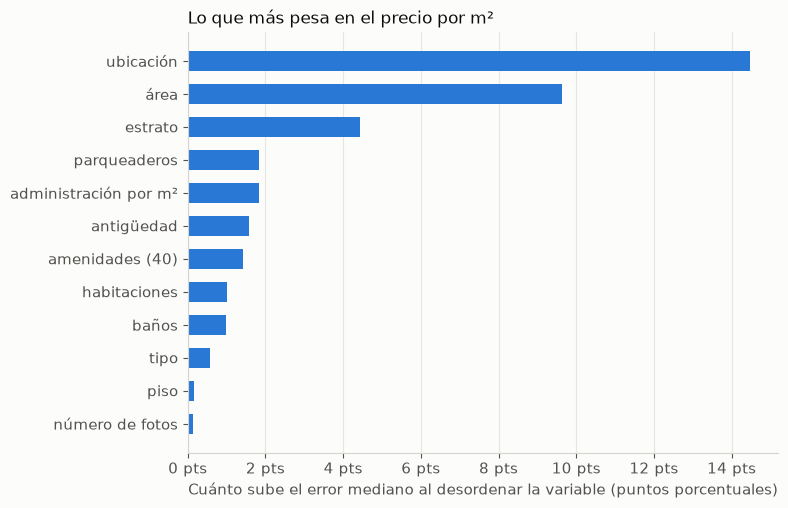

,error adicional
ubicación,+14.5 pts
área,+9.6 pts
estrato,+4.4 pts
parqueaderos,+1.8 pts
administración por m²,+1.8 pts
antigüedad,+1.6 pts
amenidades (40),+1.4 pts
habitaciones,+1.0 pts
baños,+1.0 pts
tipo,+0.6 pts


In [12]:
rng = np.random.default_rng(SEMILLA)
muestra = rng.choice(len(i_te), size=min(5000, len(i_te)), replace=False)
Xm, TEm, ym = X.iloc[i_te].iloc[muestra], TE.iloc[i_te].iloc[muestra], y[i_te][muestra]
base_err = np.median(error(predecir(modelo, Xm, TEm), ym))
UBICACION = ["latitud", "longitud", "departamento", *TE.columns]
AREA = ["m2", "m2_construido", "m2_terreno"]
AMEN = [c for c in X.columns if c.startswith("am: ")]
grupos = {"ubicación": UBICACION, "área": AREA, "amenidades (40)": AMEN}
grupos |= {c: [c] for c in X.columns if c not in UBICACION + AREA + AMEN}
imp = {}
for nombre, cols in grupos.items():
    Xp, TEp = Xm.copy(), TEm.copy()
    orden = rng.permutation(len(Xm))
    for c in cols:
        if c in Xp:
            Xp[c] = Xp[c].to_numpy()[orden]
        else:
            TEp[c] = TEp[c].to_numpy()[orden]
    imp[nombre] = np.median(error(predecir(modelo, Xp, TEp), ym)) - base_err
NOMBRES = {"admin_m2": "administración por m²", "antiguedad": "antigüedad", "banos": "baños",
           "n_imagenes": "número de fotos", "es_proyecto": "es proyecto", "estado": "estado físico",
           "piso": "piso", "tipo": "tipo", "habitaciones": "habitaciones", "parqueaderos": "parqueaderos",
           "estrato": "estrato"}
imp = pd.Series(imp).rename(index=NOMBRES).sort_values(ascending=False)

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top.index, top.to_numpy(), height=0.6, color=AZUL)
ax.xaxis.set_major_formatter(lambda v, _: f"{v * 100:.0f} pts")
ax.set_xlabel("Cuánto sube el error mediano al desordenar la variable (puntos porcentuales)")
ax.set_title("Lo que más pesa en el precio por m²", loc="left", fontsize=12, color=TINTA)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
imp.map(lambda v: f"{v * 100:+.1f} pts").to_frame("error adicional")

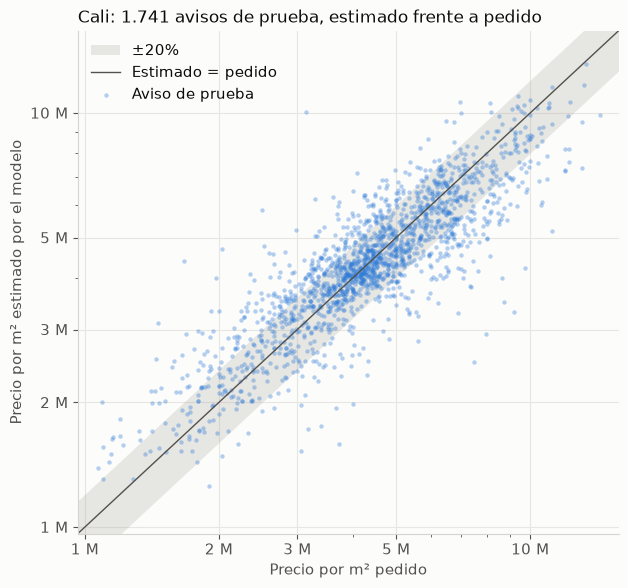

In [13]:
cali_te = prueba["ciudad"].eq("Cali").to_numpy()
real = np.exp(y[i_te][cali_te])
est = np.exp(p_mod[cali_te])
fig, ax = plt.subplots(figsize=(6.4, 6))
lim = [min(real.min(), est.min()) * 0.9, max(real.max(), est.max()) * 1.1]
xx = np.geomspace(*lim, 50)
ax.fill_between(xx, xx * 0.8, xx * 1.2, color=GRIS, alpha=0.25, linewidth=0, label="±20%")
ax.plot(xx, xx, color=TINTA_2, linewidth=1, label="Estimado = pedido")
ax.scatter(real, est, s=10, color=AZUL, alpha=0.35, linewidths=0, label="Aviso de prueba")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
fmt = lambda v, _: f"{v / 1e6:.0f} M"
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
marcas = [1e6, 2e6, 3e6, 5e6, 10e6, 20e6]
ax.set_xticks([m for m in marcas if lim[0] <= m <= lim[1]]); ax.set_yticks([m for m in marcas if lim[0] <= m <= lim[1]])
ax.xaxis.set_minor_formatter(lambda v, _: ""); ax.yaxis.set_minor_formatter(lambda v, _: "")
ax.set_xlabel("Precio por m² pedido"); ax.set_ylabel("Precio por m² estimado por el modelo")
ax.set_title(f"Cali: {mil(cali_te.sum())} avisos de prueba, estimado frente a pedido", loc="left", fontsize=12, color=TINTA)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 10. Aplicación: la alerta de Cali con el modelo

Los avisos nuevos de Cali de la semana del 20 al 26 de octubre (los que calificó la alerta con
`--fuente http`), medidos con el **modelo temporal** (entrenado solo con lo publicado antes de octubre, así
que no los vio). Se comparan dos descuentos:

- **vs. comparables** = 1 − precio/m² ÷ mediana de los comparables (lo que usa hoy la alerta)
- **vs. modelo** = 1 − precio ÷ precio estimado

Solo cifras agregadas: los avisos concretos quedan en los informes privados (`reports/`).

In [14]:
informe = BASE / "reports" / "oportunidades" / "cali_2026-10-26_http.csv"
if not informe.exists():
    print("No está el informe de la alerta (python -m src.oportunidades --fuente http); se omite esta sección.")
else:
    al = pd.read_csv(informe, dtype={"id_inmueble": str})
    al = al[al["descuento"].notna()]
    idx = pd.Series(np.arange(len(a)), index=a["id_inmueble"].astype(str).to_numpy())
    al = al[al["id_inmueble"].isin(idx.index)]
    filas_al = idx.loc[al["id_inmueble"]].to_numpy()
    est_al = np.exp(predecir(modelo_t, X.iloc[filas_al], TE.iloc[filas_al])) * a["m2"].iloc[filas_al].to_numpy()
    al["desc_modelo"] = 1 - a["precio"].iloc[filas_al].to_numpy() / est_al
    corr = al[["descuento", "desc_modelo"]].corr(method="spearman").iloc[0, 1]
    print(f"Avisos de la semana con comparables: {len(al)} · correlación (Spearman) entre los dos descuentos: {corr:.2f}")
    umbral = 0.20
    a_comps, a_mod = al["descuento"] >= umbral, al["desc_modelo"] >= umbral
    print(f"≥{umbral:.0%} bajo comparables: {a_comps.sum()} · ≥{umbral:.0%} bajo el modelo: {a_mod.sum()} · "
          f"en ambos: {(a_comps & a_mod).sum()}")
    top_c = set(al.nlargest(10, "descuento")["id_inmueble"]); top_m = set(al.nlargest(10, "desc_modelo")["id_inmueble"])
    print(f"De los 10 mayores descuentos por comparables, {len(top_c & top_m)} también están entre los 10 del modelo")
    print(f"Descuento mediano vs. modelo de los 10 primeros por comparables: "
          f"{al[al['id_inmueble'].isin(top_c)]['desc_modelo'].median():.0%}")

Avisos de la semana con comparables: 297 · correlación (Spearman) entre los dos descuentos: 0.72
≥20% bajo comparables: 36 · ≥20% bajo el modelo: 24 · en ambos: 19
De los 10 mayores descuentos por comparables, 3 también están entre los 10 del modelo
Descuento mediano vs. modelo de los 10 primeros por comparables: 19%


## 11. Conclusiones (estado del 26-oct-2026)

| | Modelo | Mediana del m² por barrio | Comparables de la alerta (Cali) |
|---|---|---|---|
| Error mediano, validación por inmueble | **11,9%** | 17,6% | — |
| Error mediano, avisos nuevos de octubre | **11,1%** | 16,2% | — |
| Error mediano en Cali, avisos con comparables | **11,1%** | — | 14,5% |
| Avisos que puede estimar | 100% | ~100% | 80% |

1. **El modelo es claramente mejor que las medianas.** Gana en las 10 ciudades con más avisos y en los
   tres tipos, también en avisos nuevos que nunca vio, y sin sesgo (−0,7%).
2. **También le gana a los comparables de la alerta** en Cali (11,1% frente a 14,5%) y estima todos los
   avisos, no solo los que tienen 8 comparables.
3. **Dónde falla más:** casas (16,5%), el 20% más caro (16,8%) y Cartagena (15,6%). En las casas pesa que el
   área mezcla lote y construcción (E4).
4. **Los rangos son honestos pero anchos.** Calibrados contienen el 79,6% de los precios (objetivo 80%),
   pero para un inmueble estimado en 400 M el rango va de ~315 a ~510 M. Sirven para un informe de
   captación; para afirmar "esto es una ganga" hay que mirar el punto y el rango juntos.
5. **Qué pesa:** ubicación y área explican la mayor parte. Les siguen estrato, parqueaderos, administración
   por m², antigüedad y amenidades. El texto de la descripción todavía no se usa.
6. **En la alerta, los dos descuentos se parecen pero no son lo mismo** (correlación 0,72). De los 36 avisos
   ≥20% bajo sus comparables, 19 también lo están frente al modelo, y de los 10 mayores descuentos por
   comparables, 3 están entre los 10 del modelo. El modelo es **más conservador**: parte del "descuento"
   por comparables se explica con lo que estos no miran (parqueaderos, antigüedad, administración,
   amenidades).

**Límites:** son precios pedidos, no de cierre; es una foto de un solo día; acertar dentro de ±10% pasa
solo en ~45% de los casos; y el modelo aprende los sesgos del portal (sobreprecios generalizados incluidos).

**Próximos pasos propuestos:**
1. **Revisar con los agentes** los avisos donde los dos descuentos más difieren: ¿cuál acertó?
2. **Alerta con modelo, en paralelo** (producto 3 del BACKLOG): mostrar "X% bajo el modelo" junto al
   descuento por comparables durante unas semanas antes de decidir cuál manda.
3. **Variables nuevas:** palabras de la descripción ("remodelado", "para remodelar", "remate"), servicios
   cercanos (`src/osm_pois.py`) y la mediana de los vecinos más cercanos.
4. **Modelo de arriendo** con el mismo esquema, para una rentabilidad estimada con modelo (E3 + E7).
5. **Para producción:** un módulo `src/modelo_precio.py` que entrene cada semana y guarde el modelo en R2.